# Group Assignment 1: Human Activity Detection
In this assignment you will create you own dataset for classification. You will explore which ML algorithms are best to classify this and you will present your best solution. 

- Create your own dataset for custom human motions using Phyphox
- There should be at least 3 distinct types of motions
- The motions should be different to the ones used in the UCI dataset (Not: walking, sitting, standing, laying, stairs)
- Follow the steps and answer the questions given in this notebook

### Generating your dataset:

For this assignment you will create your own dataset of motions that you collect with an Accelerometer and Gyroscope. For this you can use your phone as a sensor.
To be able to collect your data you can best use an app called [phyphox](https://phyphox.org/), this is a free app available in app stores. This app can be configured to acces your sensordata, sample it as given frequency's. you can set it up te have experiment timeslots, and the data with a timestamp can be exported to a needed output format.

![](https://phyphox.org/wp-content/uploads/2019/06/phyphox_dark-1024x274.png)

When you installed the app you can setup a custum experiment by clicking on the + button. Define an experiment name, sample frequency and activate the Accelerometer and Gyroscope. Your custom experiment will be added, you can run it pressing the play button and you will see sensor motion. Pressing the tree dots (...) lets you define timed runs, remote access and exporting data.

Phyphox will generate 2 files with sensor data, one for the Accelerometer and one for the Giro. Both files will have timestamps which might not match the recorded sensor data for each sensor. Please, preprocess and merge the files for using it as your dataset for training, testing and deploying your own supervised learning model.

### steps

With your own generated dataset the similar sequence of steps should be taken to train your model.

These are the generic steps to be taken
1. Frame the problem and look at the big picture.
2. Get the data.
3. Explore the data to gain insights.
4. Prepare the data to better expose the underlying data patterns to Machine Learning algorithms
5. Explore many different models and short-list the best ones.
6. Fine-tune your models and combine them into a great solution.
7. Present your solution.
8. Launch, monitor, and maintain your system.
9. Additional Questions


---
In the Notebook this structure is used for dividing the different steps, so make sure you do the implementation and analisis at these location in the notebook. 

You may add additinal code blocks, but keep the seperation of the given structure.

At the end of each block summarize / comment / conclude your current step in the given textblocks.




By:

Haakon F. Valland

Pedro Mur

Yvette Lopez

# 1. Frame the problem and look at the big picture
Describe the problem at hand and explain your approach

Responsible: Pedro

```
# Place your comments / conclusions / insight here
```
The goal of this assignment is to train a ML model that is able to detect a series of actions using accelerometer and gyroscope data from Phyphox.

# 2. Get the data.

Initialize the system, get all needed libraries, retreive the data and import it

> Create your own dataset

> Explain and show (with a few images) which motions you are classifing, how you generated them, what the problems where you encountered in this process! 

The actions chosen to be classified are: Chair spin, jumping and doing squats.

This actions were chosen because they were:
- Not part of the original human activity dataset
- Easy to replicate
- Distinct enough between eachother to make them distinguishable

The data was generated with the Phyphox app. We would all place our phones in the same pocket in our pants and realize these actions for a certain amount of time. Afterwards we would export the generated csv file.

One problem we ran into however was that that the beginning and the end of each recording (putting phone in pocket and taking it out at the end) was harmful data because the data on those sections was very different from the rest and could make training more difficult. We had to clean up this data in Excel by looking at the plot and manually cutting the beginning nd end of each recording to have proper data.

Also, we realized that in order to avoid having to record and manually clean hundreds of recordings it was best to record a long set of these actions (I.e. spinning in a chair for 2min) and then make several batches out of it.

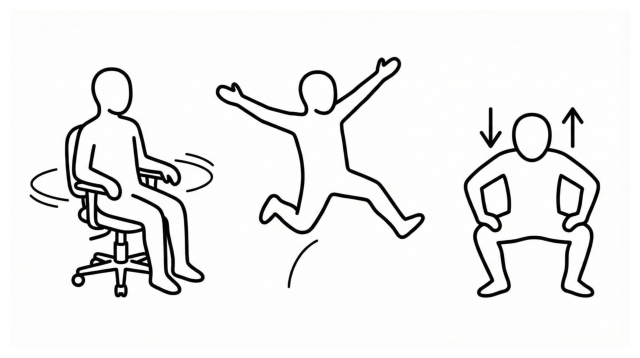

In [14]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
img = mpimg.imread('Others/Actions.png')
plt.figure(figsize=(8,6))
plt.imshow(img)
plt.axis('off')
plt.show()

In [15]:
#Responsible: Pedro
import os
import re
import math
import pandas as pd
import numpy as np

#This code processes Phyphox CSV files to extract statistical features from accelerometer and gyroscope data.
# It splits large CSV files into smaller chunks and computes mean, standard deviation, min, and max for each axis.

#CSV splitter
def split_csv_into_chunks(input_folder, output_folder=None, chunk_size=200, sep=';', decimal=','):
    if output_folder is None:
        output_folder = os.path.join(input_folder, 'snippets')
    os.makedirs(output_folder, exist_ok=True)

    for fname in os.listdir(input_folder):
        if not fname.lower().endswith('.csv'):
            continue
        in_path = os.path.join(input_folder, fname)
        try:
            df = pd.read_csv(in_path, sep=sep, decimal=decimal)
        except Exception as e:
            print(f"Skipping {fname}: read error: {e}")
            continue

        nrows = len(df)
        if nrows == 0:
            print(f"Skipping {fname}: empty file")
            continue

        base = os.path.splitext(fname)[0].replace(' ', '_')
        parts = math.ceil(nrows / chunk_size)
        for i in range(parts):
            start = i * chunk_size
            end = start + chunk_size
            chunk = df.iloc[start:end].copy()
            out_name = f"{base}_part{i+1:03d}.csv"
            out_path = os.path.join(output_folder, out_name)
            chunk.to_csv(out_path, index=False, sep=sep, decimal=decimal)
        print(f"Wrote {parts} chunks for {fname} -> {output_folder}")

    return output_folder


# 1. CHANGE THIS PATH to the folder containing your Phyphox CSV files
my_folder_path = './HumanActivity'

# Split originals into snippets
snippets_folder = split_csv_into_chunks('./HumanActivity', chunk_size=200)

Wrote 9 chunks for ChairSpin_Haakon.csv -> ./HumanActivity\snippets
Wrote 9 chunks for ChairSpin_Yvette.csv -> ./HumanActivity\snippets
Wrote 4 chunks for Jumping_Haakon.csv -> ./HumanActivity\snippets
Wrote 4 chunks for Jumping_Yvette.csv -> ./HumanActivity\snippets
Wrote 7 chunks for Squats_Haakon.csv -> ./HumanActivity\snippets
Wrote 11 chunks for Squats_Yvette.csv -> ./HumanActivity\snippets


```
# Place your comments / conclusions / insight here
```


# 3. Explore the data to gain insights.

Explore the data in any possible way, visualize the results (if you have multiple plots of the same kind of data put them in one larger plot)

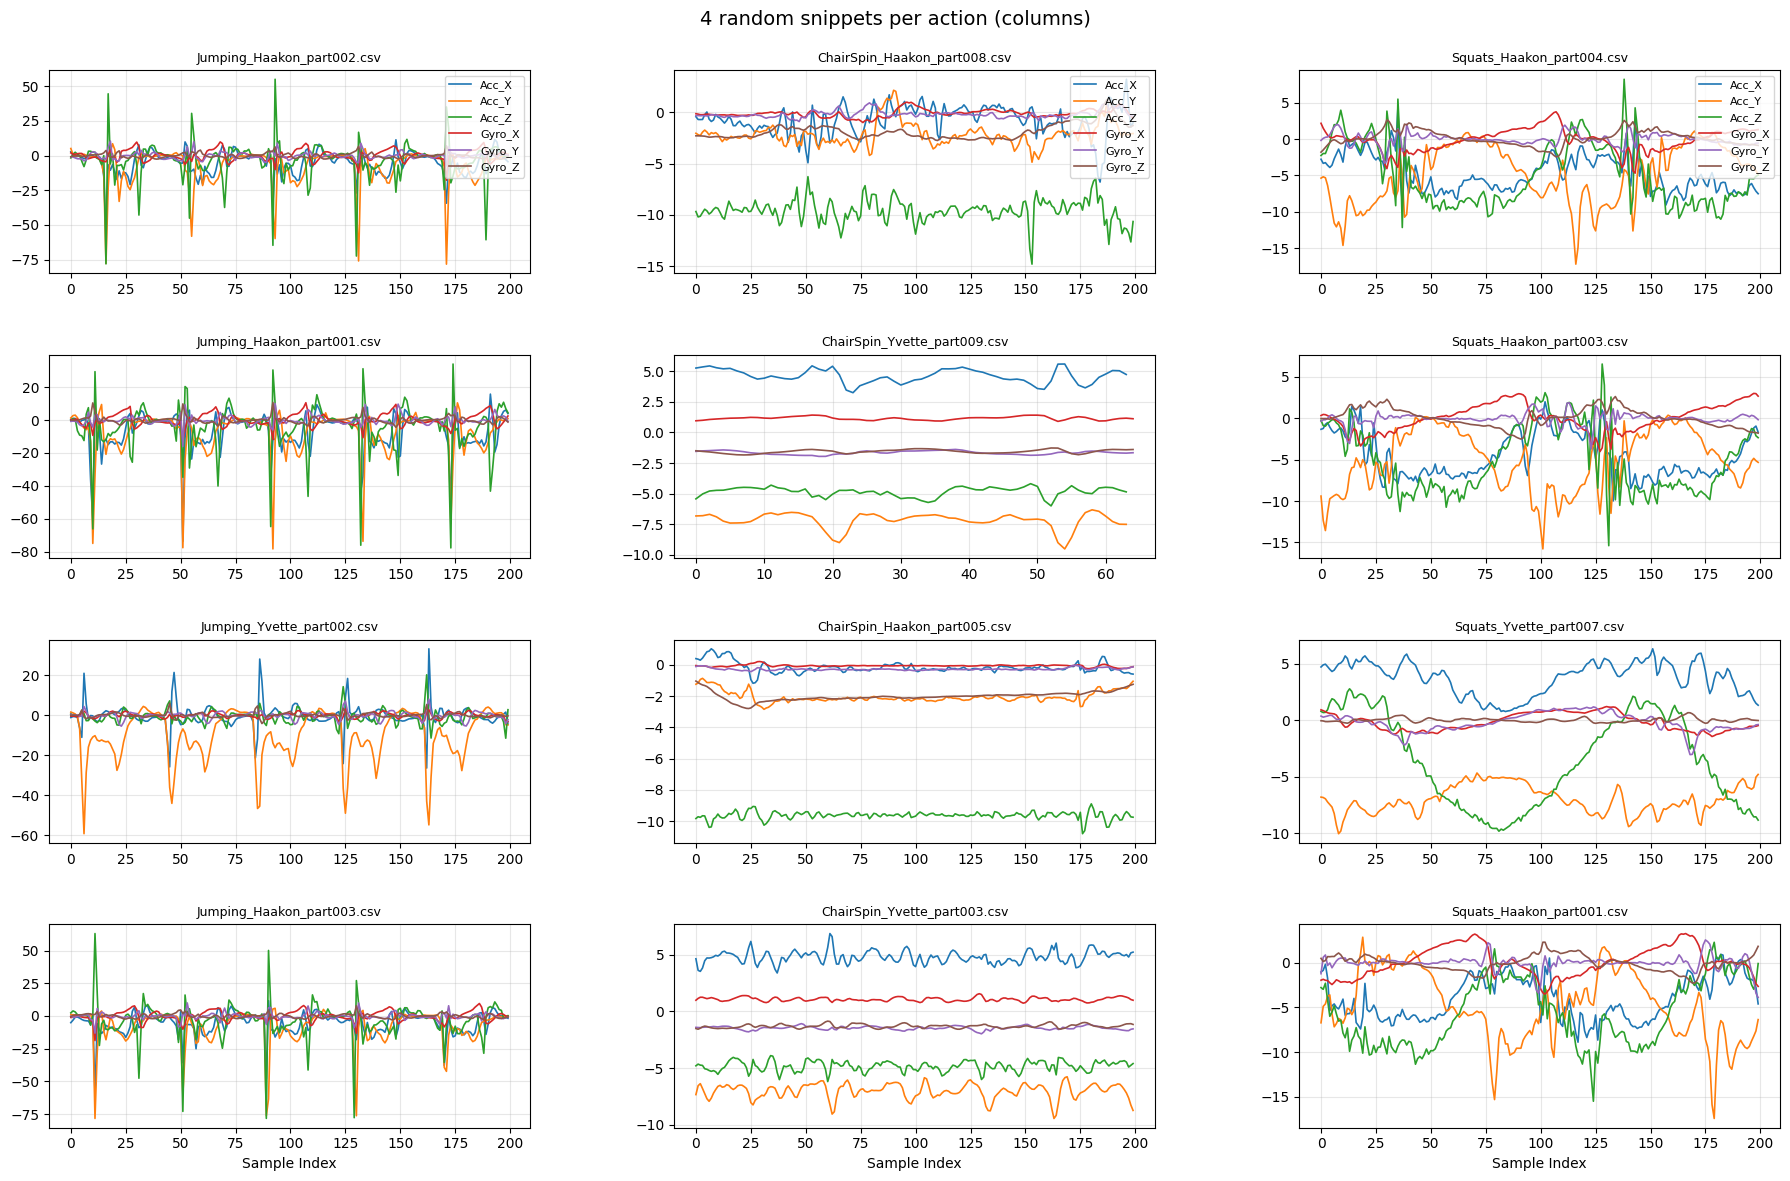

In [23]:
#Responsible: Pedro
import os
import random
import pandas as pd
import matplotlib.pyplot as plt

random.seed(42)

snippets_dir = './HumanActivity/snippets'
actions = ['Jumping', 'ChairSpin', 'Squats']   # matching text in filenames (case-insensitive)
per_action = 4

# gather files per action
files_by_action = {}
all_snippets = [f for f in os.listdir(snippets_dir) if f.endswith('.csv')]
for a in actions:
    matches = [f for f in all_snippets if a.lower() in f.lower()]
    files_by_action[a] = matches

# sample files (if fewer than required, take all available)
sampled = {a: random.sample(files_by_action[a], min(per_action, len(files_by_action[a])))
           for a in actions}

# plotting grid: 4 rows x 3 cols (rows = samples)
fig, axes = plt.subplots(per_action, len(actions), figsize=(18, 12), sharex=False)
axis_labels = ['Acc_X','Acc_Y','Acc_Z','Gyro_X','Gyro_Y','Gyro_Z']
colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown']

for col_idx, action in enumerate(actions):
    files = sampled[action]
    for row_idx in range(per_action):
        ax = axes[row_idx, col_idx] if per_action > 1 else axes[col_idx]
        if row_idx >= len(files):
            ax.axis('off')
            continue
        fname = files[row_idx]
        fpath = os.path.join(snippets_dir, fname)
        try:
            raw = pd.read_csv(fpath)                # read without explicit sep/decimal
            if raw.shape[1] == 1:
                raw = raw.iloc[:,0].astype(str).str.split(';', expand=True)
            # normalize decimals (comma -> dot) then convert to numeric
            raw = raw.map(lambda x: str(x).replace(',', '.'))
            if raw.shape[1] >= 7:
                data = raw.iloc[:, 1:7].copy()
            else:
                data = raw.iloc[:, :6].copy()
            data = data.apply(pd.to_numeric, errors='coerce')

            if data.shape[1] < 6:
                ax.text(0.5, 0.5, 'Not enough columns', ha='center', va='center')
                ax.set_title(fname)
                ax.axis('off')
                continue

            for i in range(6):
                label = axis_labels[i] if row_idx == 0 else None
                ax.plot(data.iloc[:, i].values, color=colors[i], label=label, linewidth=1.2)
            ax.set_title(fname, fontsize=9)
            if row_idx == 0:
                ax.legend(loc='upper right', fontsize=8)
            ax.grid(alpha=0.3)
            if row_idx == per_action - 1:
                ax.set_xlabel('Sample Index')
        except Exception as e:
            ax.text(0.5, 0.5, f'Error: {e}', ha='center', va='center')
            ax.set_title(fname)

plt.suptitle('4 random snippets per action (columns)', fontsize=14)
plt.tight_layout()
plt.subplots_adjust(top=0.93, hspace=0.4, wspace=0.3)
plt.show()

```
# Place your comments / conclusions / insight here
```
From the plots we can observe that the three actions have very disctinct plots.
- Jumping has values close to zero except very high acceleration spikes periodically.
- Squats have gradually changing accelerations that plot something like a weaving sine waves
- Chair spin doesnt have spikes or sine waves. All measurements stay at 0 or close to zero and maintain that constant value.



# 4. Prepare the data to better expose the underlying data patterns to Machine Learning algorithms

prepare your data, is it normalized? are there outlier? Make a training and a test set.

In [17]:
# Responsible: Pedro

#Feature extractor
def extract_axis_features_from_folder(folder_path):
    features_list = []
    file_names = []
    action_list = []
    name_list = []

    col_labels = ['Acc_X', 'Acc_Y', 'Acc_Z', 'Gyro_X', 'Gyro_Y', 'Gyro_Z']

    for file in os.listdir(folder_path):
        if file.endswith(".csv"):
            file_path = os.path.join(folder_path, file)
            try:
                df = pd.read_csv(file_path)
                if df.shape[1] >= 7:
                    data = df.iloc[:, 1:7]
                elif df.shape[1] == 6:
                    data = df.iloc[:, :6]
                else:
                    print(f"Skipping {file}: Not enough columns found ({df.shape[1]} columns).")
                    continue

                data = data.apply(pd.to_numeric, errors='coerce')
                if data.empty:
                    print(f"Skipping {file}: Data frame is empty after selection.")
                    continue

                means = data.mean().values
                stds = data.std().values
                mins = data.min().values
                maxs = data.max().values
                feature_vector = np.concatenate([means, stds, mins, maxs])

                features_list.append(feature_vector)
                file_names.append(file)

                # parse Action and Name from filename (handles underscores, spaces or dashes)
                base = os.path.splitext(file)[0]
                parts = re.split('[ _-]+', base)
                action = parts[0] if len(parts) >= 1 else ''
                name = parts[1] if len(parts) >= 2 else ''
                action_list.append(action)
                name_list.append(name)

            except Exception as e:
                print(f"Error processing {file}: {e}")

    stats = ['Mean', 'Std', 'Min', 'Max']
    final_headers = [f"{stat}_{col}" for stat in stats for col in col_labels]

    result_df = pd.DataFrame(features_list, columns=final_headers)
    result_df.insert(0, 'Action', action_list)
    result_df.insert(1, 'Name', name_list)

    return result_df

# 2. Run the functionfeature extractor
features_df = extract_axis_features_from_folder(snippets_folder)

# Print the result (First 5 rows)
print("\nFeatures extracted successfully:")
print(features_df.head())
    
# 3. Optional: Save the features to a new CSV file ready for training
output_file_name = 'extracted_features.csv'
features_df.to_csv(output_file_name, index=False)
print(f"\nFeatures saved to {output_file_name}")


Features extracted successfully:
      Action    Name  Mean_Acc_X  Mean_Acc_Y  Mean_Acc_Z  Mean_Gyro_X  \
0  ChairSpin  Haakon   -0.115424   -1.169192   -9.735004     0.052886   
1  ChairSpin  Haakon   -0.455341   -1.958385   -9.625230     0.047596   
2  ChairSpin  Haakon   -0.687627   -2.039453   -9.581057    -0.114867   
3  ChairSpin  Haakon   -0.205219   -1.987786   -9.660855     0.079128   
4  ChairSpin  Haakon   -0.165571   -2.046372   -9.638446    -0.060408   

   Mean_Gyro_Y  Mean_Gyro_Z  Std_Acc_X  Std_Acc_Y  ...  Min_Acc_Z  Min_Gyro_X  \
0    -0.012165    -1.191068   1.302610   1.361731  ... -12.960114   -2.181247   
1     0.110738     0.929172   1.080670   0.589112  ... -11.360786   -0.409738   
2    -0.202560    -1.348204   0.711471   0.749860  ... -11.700763   -0.618043   
3     0.264401     1.760850   0.424067   0.523030  ... -11.545140   -0.115301   
4    -0.277568    -2.009279   0.346962   0.363759  ... -10.807726   -0.246637   

   Min_Gyro_Y  Min_Gyro_Z  Max_Acc_X  Ma

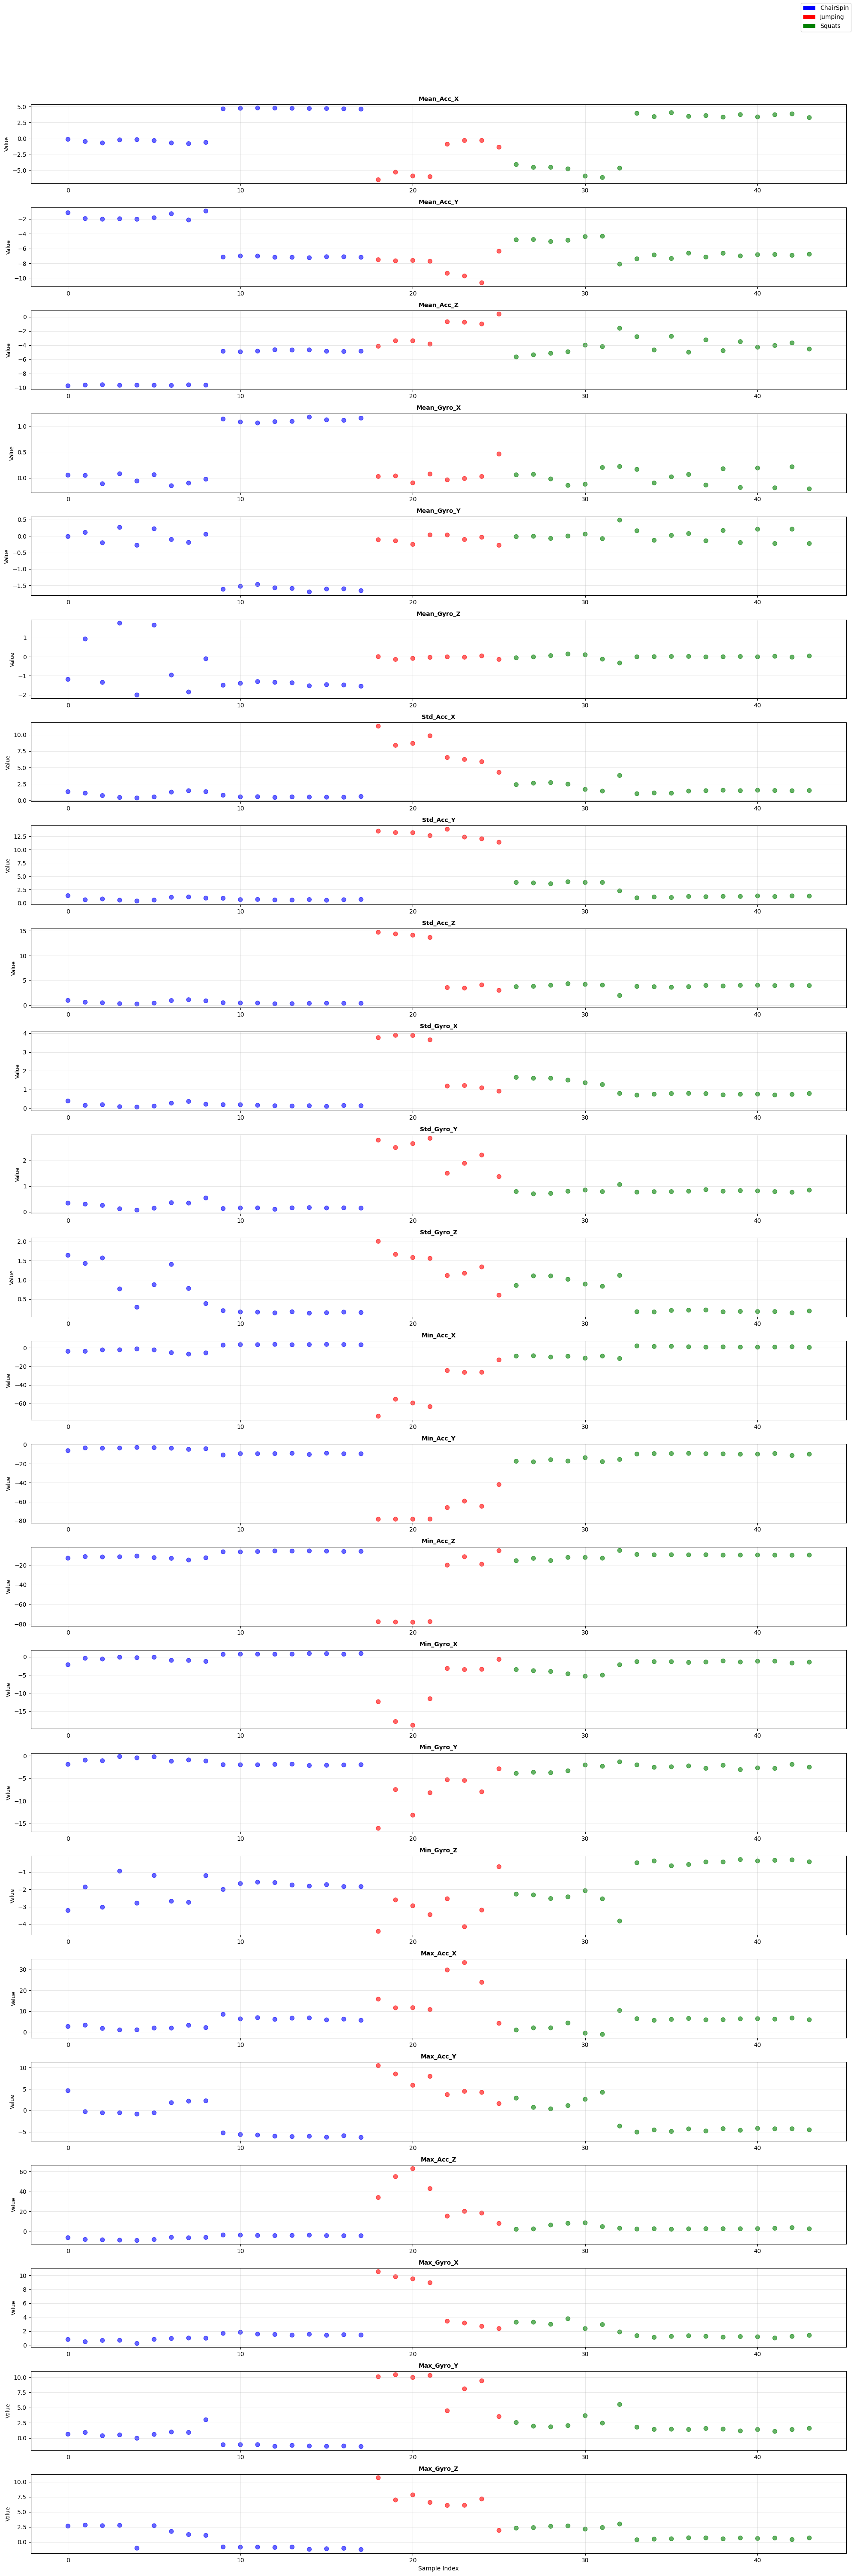

In [18]:
# Load the extracted features
features_file = 'extracted_features.csv'
features_df = pd.read_csv(features_file)

# Separate categorical and numeric columns
categorical_cols = ['Action', 'Name']
numeric_cols = [col for col in features_df.columns if col not in categorical_cols]

# Create subplots for each feature
fig, axes = plt.subplots(len(numeric_cols), 1, figsize=(20, 60))

# Color by action for visualization
action_colors = {'ChairSpin': 'blue', 'Jumping': 'red', 'Squats': 'green'}
colors = [action_colors.get(action, 'gray') for action in features_df['Action']]

for idx, col in enumerate(numeric_cols):
    axes[idx].scatter(range(len(features_df)), features_df[col], c=colors, alpha=0.6, s=50)
    axes[idx].set_title(f'{col}', fontsize=10, fontweight='bold')
    axes[idx].set_ylabel('Value', fontsize=9)
    axes[idx].grid(True, alpha=0.3)

axes[-1].set_xlabel('Sample Index', fontsize=10)

# Add legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='blue', label='ChairSpin'),
                   Patch(facecolor='red', label='Jumping'),
                   Patch(facecolor='green', label='Squats')]
fig.legend(handles=legend_elements, loc='upper right', fontsize=10)

plt.tight_layout()
plt.subplots_adjust(top=0.96)
plt.show()

In [19]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('extracted_features.csv')

if 'Action' in df.columns:
    train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Action'], random_state=42)
else:
    train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

train_df = train_df.sample(frac=1, random_state=42).reset_index(drop=True)
test_df  = test_df.sample(frac=1,  random_state=42).reset_index(drop=True)

train_df.to_csv('train_features.csv', index=False)
test_df.to_csv('test_features.csv', index=False)

print(f"Saved train: {len(train_df)} rows -> train_features.csv")
print(f"Saved test : {len(test_df)} rows -> test_features.csv")

Saved train: 35 rows -> train_features.csv
Saved test : 9 rows -> test_features.csv


```
# Place your comments / conclusions / insight here
```
From the features extracted we can 


# 5. Explore many different models and short-list the best ones.

Explore / train and list the top 3 algorithms that score best on this dataset.

In [20]:
#Responsible: Haakon

# YOUR CODE HERE 



```
# Place your comments / conclusions / insight here
```


# 6. Fine-tune your models and combine them into a great solution.

can you get better performance within a model? e.g if you use a KNN classifier how does it behave if you change K (k=3 vs k=5 vs k=?). Which parameters are here to tune in the chosen models? 

In [21]:
#Responsible: Haakon
# YOUR CODE HERE 

```
# Place your comments / conclusions / insight here
```


# 7. Present your solution.

Explain why you would choose for a specific model

In [22]:
#Responsible: Haakon
# YOUR CODE HERE 

```
# Place your comments / conclusions / insight here
```


# 8. Launch, monitor, and maintain your system.

Responsible: Yvette

Can you Deployment the model?

> NOTE: The app provides the option for remote access, so you are able to get live sensordata from the phone

# 9. Additional Questions

Responsible: Yvette

* Explain the chosen motions you chose to be classified. 

* Which of these motions is easier/harder to classify and why?

* After your experience, which extra sensor data might help getting a better classifier and why?

* Explain why you think that your chosen algorithm outperforms the rest? 

* While recording the same motions with the same sensor data, what do you think will help improving the performance of your models?


```
# Place your comments / conclusions / insight here
```
